# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr Luis Eduardo Falcón Morales**

**Tecnológico de Monterrey**
### **Actividad Individual: Pronósticos con Series de Tiempo**


#### **Nombre: Lizbeth Celeste Duron Escareño**
#### **Matrícula: A01748476**

Modelos para predicción de un problema de serie de tiempo:

* **1. Modelo ingenuo**
* **2. Modelo ARIMA**
* **3. Modelo Prophet**
* **4. Modelo LSTM**


NOTA: Recuerda que cada modelo puede llegar a tener una gran cantidad de hiperparámetros y tipo de ajsutes, por lo que siempre inicia con un modelo sencillo y de ahí buscar mejorar su resultado. Esto para no desgastarte desde un inicio buscando la mayor cantidad de ajustes e hiperparámetros.

# **A - Introducción**

In [59]:
# Agrega aquí todas las librerías y paquetes adicionales que requieras.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet


from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
import keras
from keras import Sequential
from keras import layers
from keras.layers import LSTM, Dense


# **Ejercicio 1**

* **1a. De la página de Google-Trends generar y descargar los datos con períodos mensuales que se obtienen con el término de búsqueda "chocolate", del país "Estados Unidos", de los últimos 20 años (del 1 de marzo del 2006 al 28 de febrero del 2026) y con las opciones de "todas las categorías" y "búsqueda de web". De manera predeterminada se generan datos mensuales.**

* **1b. Cargar los datos en un DataFrame de Pandas llamado "dfp" y con los nombres"ds" y "y" para las columnas de fechas y porcentajes de interés de búsqueda, respectivamente. Las fechas ajustarlas al formato YYYY-MM-DD, con días de fin de mes. Este formato es el que se requiere para el modelo Prophet.**

* **1c. A partir del DataFrame "dfp", genera ahora el DataFrame que llamaremos "dfr" para el resto de los modelos. El formato en "dfr" requerido para el resto de los modelos debe tener la primera columna de fechas de "dfp" ahora como índice del DataFrame "dfr". Además, el índice de fechas debe tener una frecuencia mensual al final del mes.**



https://trends.google.es/trends/



In [44]:
# Ejercicios 1a y 1b.

# ************* Inlcuye aquí tu código:*****************************

path = '/content/multiTimeline.csv'
df = pd.read_csv(path, skiprows=2)

# Crear dfp con columnas "ds" y "y"
dfp = df.copy()
dfp.columns = ["ds", "y"]

# Convertir "YYYY-MM" a fecha
dfp["ds"] = pd.to_datetime(dfp["ds"], format="%Y-%m") + pd.offsets.MonthEnd(0)

# Asegurar que "y" sea numérica
dfp["y"] = pd.to_numeric(dfp["y"], errors="coerce")

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (240, 2)
          ds   y
0 2006-03-31  32
1 2006-04-30  34
2 2006-05-31  32
3 2006-06-30  28
4 2006-07-31  30
            ds    y
235 2025-10-31   66
236 2025-11-30   79
237 2025-12-31  100
238 2026-01-31   75
239 2026-02-28   81


In [45]:
# Ejercicio 1c.

# ************* Inlcuye aquí tu código:*****************************

dfr = dfp.copy()

# La columna -> índice
dfr = dfp.copy()

# La columna de fechas pasa a ser el índice
dfr.set_index('ds', inplace=True)

# Frecuencia mensual a fin de mes
dfr.freq = 'MS'  # MS-Month-start-frequency o M=ME-Month-end-frequency


# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por los modelos restantes:
(240, 1)
             y
ds            
2006-03-31  32
2006-04-30  34
2006-05-31  32
2006-06-30  28
2006-07-31  30
DatetimeIndex(['2006-03-31', '2006-04-30', '2006-05-31', '2006-06-30',
               '2006-07-31', '2006-08-31', '2006-09-30', '2006-10-31',
               '2006-11-30', '2006-12-31',
               ...
               '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31',
               '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31',
               '2026-01-31', '2026-02-28'],
              dtype='datetime64[ns]', name='ds', length=240, freq=None)


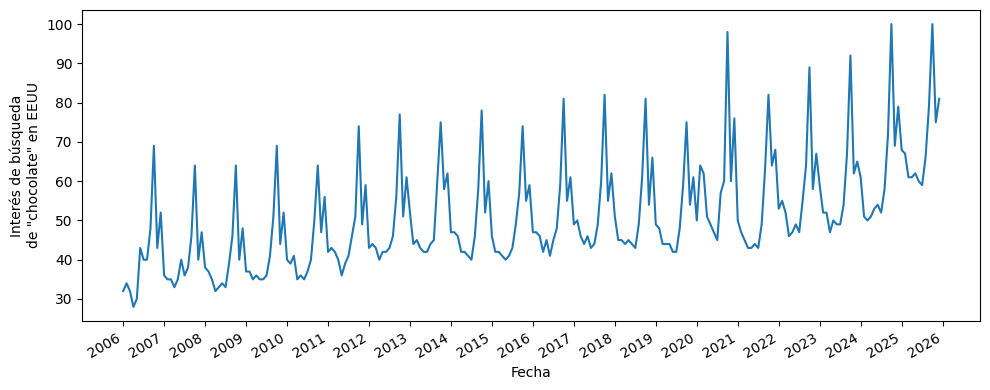

In [46]:
# Veamos el comportamiento de la serie de tiempo, en particular usemos dfp:

plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde \"chocolate\" en EEUU')

xticks_locs = np.arange(0, len(dfp)+12, 12) # lista: 0,12,24,36,...,240... cada 12 meses se agregará una etiqueta del año.
xticks_labels = np.arange(2006, 2027, 1)
plt.xticks(xticks_locs, xticks_labels)

fig.autofmt_xdate()
plt.tight_layout()

In [47]:
# Partición:
# Particionamos en conjunto de Prueba, Validación y Prueba de acuerdo a
# datos de una serie de tiempo y considerando el caso Prophet y el resto
# de los modelos.
# Hacemos esta diferenciación solo por fines prácticos de la actividad y
# en su momento utilizar los conjuntos respectivos en cada caso de manera
# más sencilla en la actividad.

# Para el modelo Prophet:
testP = dfp[-12:]      # El último año para prueba.
valP = dfp[-24:-12]    # El penúltimo año para validación.
trainP = dfp[:-24]     # El resto de los primeros datos para entrenamiento.

# Para el resto de los modelos:
testR = dfr[-12:]
valR = dfr[-24:-12]
trainR = dfr[:-24]


* **El objetivo de esta actividad es encontrar un modelo que pueda predecir el interés de búsqueda de la palabra "chocolate" en el navegador de Google para el próximo año. Para ello, buscaremos el modelo entrenando y validando con los conjuntos Train y Val, midiendo el desempeño con el error MAE. Con el mejor modelo encontrado obtendremos el desempeño final con el conjnuto de Prueba (Test).**

# **B - Modelo ingenuo**

# **Ejercicio - 2**

* **Iniciemos con el modelo base o ingenuo (naive/baseline).**

* **2a. En esta actividad usaremos la métrica del Error Absoluto Medio, MAE por sus siglas en inglés, "Mean Absolute Error", para monitorear el desempeño de nuestros modelos. Enuncia ventajas y desventajas de usar MAE en comparación con el error cuadrático medio MSE.**

* **2b. Encontrar e imprimir el valor del desempeño del modelo ingenuo con respecto al error MAE, llamarlo maeNaive. Utiliza el conjunto de entrenamiento trainR y como conjunto de validación valR.**

* **2c. ¿Cómo interpretas el valor MAE obtenido con el modelo ingenuo en el contexto del problema?**

* **2d. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ingenuo, junto con los valores reales.**

**Ejercicio 2a:**

*Ventajas:*

*   Se entiende de forma rápida: Viene en las mismas unidades que lo que predecimos. Al MSE se le debe de sacar la raíz para poder interpretarlo.
*   Es robusto ante los outliers: Debido a que el error crece de forma lineal, un dato extremo no domina la métrica. En el MSE, el término cuadrático hace que unos pocos errores grandes puedan explicar casi toda la pérdida.
*   Todos los errores pesan proporcionalmente
*   Apunta a la mediana: Al minimizar el MAE, el modelo tiende a predecir la mediana, que es más confiable que la media cuando los datos están muy sesgados.
*    Monitoreo más estable: Al ser menos sensible a picos aislados, genera menos falsas alarmas al vigilar el desempeño del modelo en producción, aunque conviene complementarlo con otras métricas.

*Desventajas:*

*    No penaliza con mayor severidad los errores grandes: Si en el problema un error grande es desproporcionadamente costoso, el MAE no refleja esa gravedad y el MSE sí.
*    El MAE no es diferenciable en cero, porque |x| tiene un punto anguloso ahí, lo que complica la optimización con gradiente.
*    Gradiente de magnitud constante: Su gradiente tiene valor ±1 sin importar qué tan cerca esté de la solución, lo que puede causar oscilaciones cerca del óptimo si la tasa de aprendizaje no se reduce. En el MSE el gradiente disminuye al acercarse al mínimo, favoreciendo la convergencia.
*    Menor respaldo teórico: El MSE se relaciona con la estimación por máxima verosimilitud bajo errores gaussianos y con la descomposición sesgo-varianza. El MAE corresponde a errores con distribución Laplace y tiene un marco analítico menos conveniente.
*    El mínimo puede no ser único: El mínimo del MAE puede no ser único, mientras que el MSE es estrictamente convexo y tiene un único mínimo.
*    Dependencia de la escala: Igual que el MSE, no permite comparar modelos entre variables con escalas distintas sin normalizar.


In [48]:
# Ejercicio 2b:

# ************* Inlcuye aquí tu código:*****************************

# "history" es en donde de manera incremental se irán agregando registros mensuales.
history = [x for x in trainR['y'].values]

# Lista que contendrá las predicciones del modelo ingenuo.
predictions = list()

for i in range(len(testR['y'])):
  yhat = history[-1]
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = valR.iloc[i]['y']
  history.append(obs)
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Raíz del error cuadrático medio (RMSE):
maeNaive = mean_absolute_error(valR['y'].values, predictions)

# *********** Aquí termina la sección de agregar código *************


print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)


>Esperado-real =  61, Predicción = 65.000
>Esperado-real =  51, Predicción = 61.000
>Esperado-real =  50, Predicción = 51.000
>Esperado-real =  51, Predicción = 50.000
>Esperado-real =  53, Predicción = 51.000
>Esperado-real =  54, Predicción = 53.000
>Esperado-real =  52, Predicción = 54.000
>Esperado-real =  58, Predicción = 52.000
>Esperado-real =  72, Predicción = 58.000
>Esperado-real = 100, Predicción = 72.000
>Esperado-real =  69, Predicción = 100.000
>Esperado-real =  79, Predicción = 69.000

Error-modelo-Naive : MAE: 9.167


**Ejercicio 2c:**

++++++++ Inicia la sección de agregar texto: +++++++++++


El modelo ingenuo obtuvo un MAE de 9.167, lo que indica que en promedio sus predicciones se desvían aproximadamente 9 unidades del valor real en el conjunto de validación. Este valor servirá como línea base para comparar el desempeño de los modelos posteriores.


++++++++ Termina la sección de agregar texto. +++++++++++

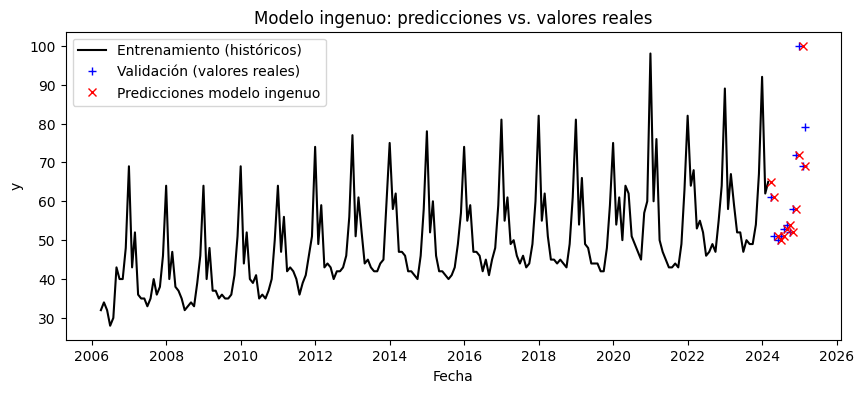

In [49]:
# Ejercicio 2d:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(trainR['y'], '-k', label='Entrenamiento (históricos)')
ax.plot(valR['y'], '+b', label='Validación (valores reales)')
ax.plot(valR.index, predictions, 'xr', label='Predicciones modelo ingenuo')

ax.set_title('Modelo ingenuo: predicciones vs. valores reales')
ax.set_xlabel('Fecha')
ax.set_ylabel('y')
ax.legend()
plt.show()

# *********** Aquí termina la sección de agregar código *************


# **C - modelo ARIMA**

# **Ejercicio - 3**

* **3a. Aplica el modelo ARIMA con los conjuntos de entrenamiento y validación trainR y valR, usando como métrica el error absoluto medio. Llamar al error maeARIMA.**

* **3b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ARIMA, junto con los valores reales.**

In [51]:
# Ejercicio 3a - ARIMA

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

#Quitar estacionalidad
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)

# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]

# Se define la lista de registros en el tiempo:
history = [x for x in trainR.loc[:,'y'].values]

predictionsArima = list()

for i in range(len(valR['y'])):
  months_in_year = 12
  diff = difference(history, months_in_year)

  # Generamos el modelo.
  model = ARIMA(diff, order=(3,0,13),)
  model_fit = model.fit(method_kwargs={'maxiter':300})

  yhat = model_fit.forecast()[0]
  yhat = inverse_difference(history, yhat, months_in_year)
  predictionsArima.append(yhat)

  # Observaciones-reales:
  obs = valR.iloc[i]['y']
  history.append(obs)

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error absoluto medio (MAE):
maeARIMA = mean_absolute_error(valR['y'].values, predictionsArima)
print('\nError-Modelo-ARIMA: MAE: %.3f' % maeARIMA)



/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real =  61, Predicción = 55.421


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real =  51, Predicción = 54.929


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real =  50, Predicción = 53.357


... (15 outputs left out)

>Esperado-real =  69, Predicción = 67.690


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


>Esperado-real =  79, Predicción = 75.104

Error-Modelo-ARIMA: MAE: 3.414


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


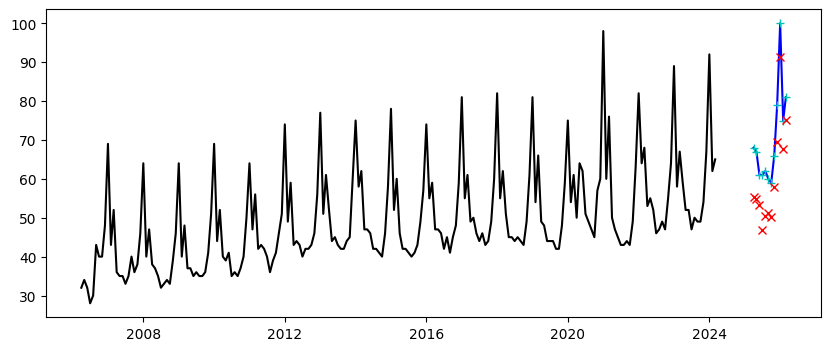

In [53]:
# Ejercicio 3b. ARIMA-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 4))
ax = plt.plot(trainR['y'], '-k')
ax = plt.plot(testR['y'], '-b')
ax = plt.plot(testR['y'], '+c')
ax = plt.plot(testR.index, predictionsArima, 'xr')


# *********** Aquí termina la sección de agregar código *************

# **D - modelo Prophet**

# **Ejercicio - 4**

* **4a. Aplica el modelo Prophet con los conjuntos de entrenamiento y validación trainP y valP, usando como métrica el error absoluto medio. Llamar al error maeProphet.**

* **4b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo Prophet-Facebook, junto con los valores reales.**

NOTA: Recuerda siempre iniciar con un modelo sencillo y de ahí buscar la mejor configuración.

In [55]:
# Ejercicio 4a - Prophet

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

model = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=18)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(trainP)

pred_FP = model.predict(valP)['yhat']

# Error absoluto medio (MAE):
maeProphet = mean_absolute_error(valP['y'], pred_FP)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [56]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 6.188


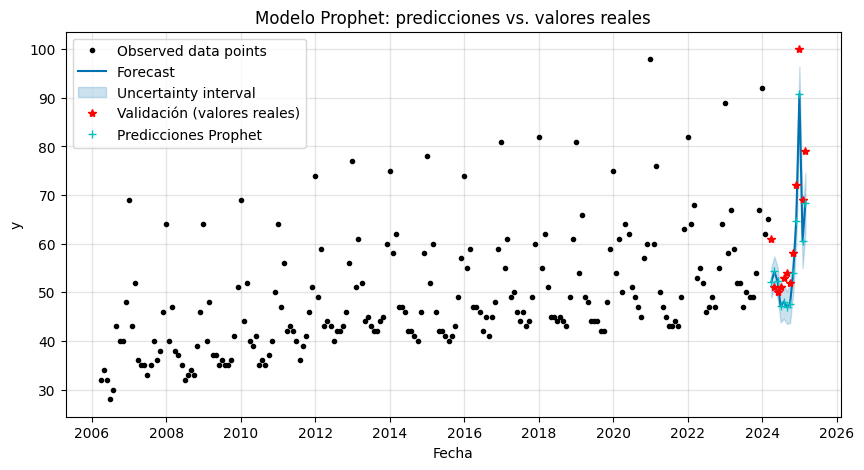

In [58]:
# Ejercicio 4b. Prophet-gráfica:

# ************* Inlcuye aquí tu código:*****************************

forecast = model.predict(valP)

fig, ax = plt.subplots(figsize=(10, 5))
model.plot(forecast, ax=ax)   # Línea continua azul: predicciones, con su región de incertidumbre.

ax.plot(valP['ds'], valP['y'], '*r', label='Validación (valores reales)')
ax.plot(valP['ds'], forecast['yhat'], '+c', label='Predicciones Prophet')

ax.set_title('Modelo Prophet: predicciones vs. valores reales')
ax.set_xlabel('Fecha')
ax.set_ylabel('y')
ax.legend()
plt.show()



# *********** Aquí termina la sección de agregar código *************

# **E - modelo LSTM (Deep Learning)**

# **Ejercicio - 5**

* **5a. Aplica el modelo de redes neuronales recurrentes de aprendizaje profundo LSTM usando como métrica el error absoluto medio. Llamar al error maeLSTM. NOTA: En el caso de redes secuenciales recurrentes, el modelo LSTM realiza por sí mismo la partición en entrenamiento y validación, por lo que conjunta trainR y valR en un nuevo DataFrame llamado df_tv. Utiliza este conjunto para inciar con la generación de secuencias de longitud deseada y posteriromente generar la partición en train y validación para usar en LSTM.**

* **5b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo LSTM, junto con los valores reales.**



#### **NOTA: En general, recordemos que los modelos basados en redes neuronales son afectados de manera importante cuando la escala de los datos se va incrementando. Por ello, en este caso podría ser conveniente escalar los datos de nuestra variable temporal, por ejemplo entre 0 y 1. Tomarlo en cuenta para que al final puedes realizar las predicciones en las unidades originales.**

In [60]:
# Ejercicio 5a - LSTM

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++
# 1. Conjuntamos trainR y valR en un solo DataFrame:
df_tv = pd.concat([trainR, valR])

# 2. Escalamos los datos al rango [0, 1]:
scaler = MinMaxScaler()
datos = scaler.fit_transform(df_tv[['y']].values)

# 3. Generamos las secuencias de longitud "seq_len":
seq_len = 12   # número de meses que el modelo "ve" para predecir el siguiente

X, y = [], []
for i in range(seq_len, len(datos)):
    X.append(datos[i-seq_len:i, 0])   # los 12 meses anteriores
    y.append(datos[i, 0])             # el mes siguiente (lo que se predice)
X = np.array(X).reshape(-1, seq_len, 1)   # formato 3D: (muestras, pasos, características)
y = np.array(y)

# 4. Partición en entrenamiento y validación (los últimos 12 meses para validar):
X_train, y_train = X[:-12], y[:-12]
X_test, y_test = X[-12:], y[-12:]

# 5. Modelo secuencial basado en LSTMs:
model = Sequential()
model.add(LSTM(50,
               return_sequences=True,
               activation='relu',
               recurrent_activation='sigmoid'))
model.add(LSTM(50, return_sequences=False, activation='relu'))
model.add(Dense(1))

model.compile(optimizer='adam',
              loss='mean_squared_error',
              metrics=[tf.keras.metrics.MeanAbsoluteError()])   # despliega MAE

history = model.fit(X_train, y_train, epochs=65, batch_size=32,
                    validation_data=(X_test, y_test))

# 6. Predicción de los últimos 12 meses:
pred_LSTM = model.predict(X_test)

# Regresamos a la escala original:
pred_LSTM = scaler.inverse_transform(pred_LSTM)
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1))

# 7. Error absoluto medio (MAE) en la escala original:
maeLSTM = mean_absolute_error(y_test_real, pred_LSTM)



Epoch 1/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - loss: 0.0998 - mean_absolute_error: 0.2678 - val_loss: 0.1830 - val_mean_absolute_error: 0.3768
Epoch 2/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0602 - mean_absolute_error: 0.1846 - val_loss: 0.0945 - val_mean_absolute_error: 0.2308
Epoch 3/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0276 - mean_absolute_error: 0.1259 - val_loss: 0.0408 - val_mean_absolute_error: 0.1633
Epoch 4/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0319 - mean_absolute_error: 0.1552 - val_loss: 0.0472 - val_mean_absolute_error: 0.1504
Epoch 5/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0257 - mean_absolute_error: 0.1233 - val_loss: 0.0661 - val_mean_absolute_error: 0.1615
Epoch 6/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0265 - mean_absolute_error: 0.1173 - val_loss: 0.0590 - val_mean_absolute_error: 0.1521
Epoch 7/65
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0252 - mean_absolute_error: 0.1232 - val_loss: 0.0481 - val

In [61]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)


Error-modelo-LSTM : MAE: 3.128


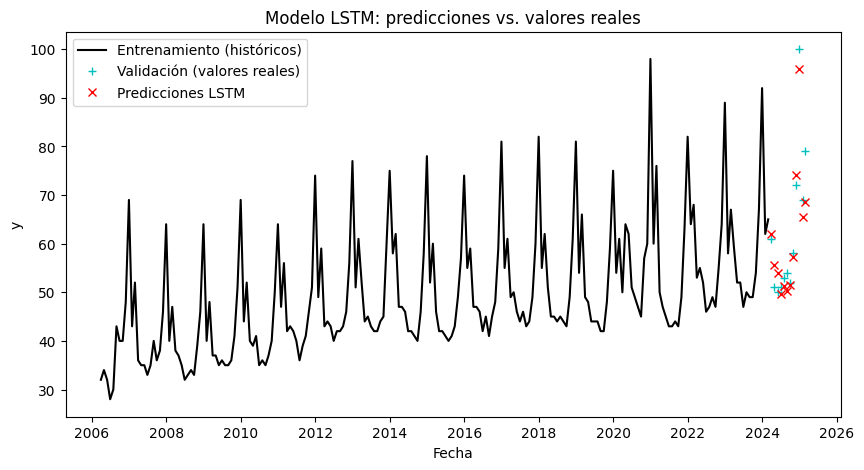

In [63]:
# Ejercicio 5b. LSTM-gráfica:

# ************* Inlcuye aquí tu código:*****************************

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df_tv.index[:-12], df_tv['y'][:-12], '-k', label='Entrenamiento (históricos)')
ax.plot(df_tv.index[-12:], df_tv['y'][-12:], '+c', label='Validación (valores reales)')
ax.plot(df_tv.index[-12:], pred_LSTM, 'xr', label='Predicciones LSTM')

ax.set_title('Modelo LSTM: predicciones vs. valores reales')
ax.set_xlabel('Fecha')
ax.set_ylabel('y')
ax.legend()
plt.show()



# *********** Aquí termina la sección de agregar código *************

# **F - Conjunto de Prueba y Conclusiones Finales**

# **Ejercicio - 6**

* **Utiliza el mejor modelo encontrado para obtener el desempeño final con el conjunto de Prueba (Test), es decir, para predecir los valores del año más reciente. Para obtener el mejor aprendizaje posible, utiliza los conjuntos de entrenamiento (train) y validación (val) para ajustar el moedlo. Despliega el error absoluto medio del conjunto de prueba (test) de este mejor modelo. Llamarlo maeMejor.**

In [65]:
# Ejercicio 6 - mejor modelo

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

tf.keras.utils.set_random_seed(42)   # para resultados reproducibles

# Unimos train, val y test para generar las secuencias:
df_all = pd.concat([trainR, valR, testR])
n_test = len(testR)

# Ajustamos el escalador solo con train + val (para no usar información de test):
scaler = MinMaxScaler()
scaler.fit(pd.concat([trainR, valR])[['y']].values)
datos = scaler.transform(df_all[['y']].values)

# Generamos las secuencias de longitud "seq_len":
seq_len = 12
X, y = [], []
for i in range(seq_len, len(datos)):
    X.append(datos[i-seq_len:i, 0])
    y.append(datos[i, 0])
X = np.array(X).reshape(-1, seq_len, 1)
y = np.array(y)

# Entrenamiento (train + val) y prueba (últimos n_test meses):
X_trainval, y_trainval = X[:-n_test], y[:-n_test]
X_test, y_test = X[-n_test:], y[-n_test:]

# Mismo modelo que usaste en la validación:
model = Sequential()
model.add(LSTM(50, return_sequences=True, activation='relu', recurrent_activation='sigmoid'))
model.add(LSTM(50, return_sequences=False, activation='relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

model.fit(X_trainval, y_trainval, epochs=65, batch_size=32, verbose=0)

# Predicción en test, regresando a la escala original:
pred_mejor = scaler.inverse_transform(model.predict(X_test))
y_real = scaler.inverse_transform(y_test.reshape(-1, 1))

# Error absoluto medio en Test:
maeMejor = mean_absolute_error(y_real, pred_mejor)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step


In [66]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)


Error-del-mejor-modelo-Test : MAE: 8.554


# **Ejercicio - 7**

* **Incluye tus comentarios y conclusiones finales de la actividad.**


++++++++ Inicia la sección de agregar texto: +++++++++++

En esta actividad se compararon cuatro modelos para pronosticar la serie de tiempo, usando el error absoluto medio (MAE) como métrica en el conjunto de validación. El modelo ingenuo obtuvo un MAE de 9.167, que sirvió como línea base; Prophet logró 6.188, ARIMA 3.414 y LSTM 3.128. Todos los modelos mejoraron al ingenuo, y el LSTM fue el de mejor desempeño, aunque con una ventaja pequeña frente al ARIMA. Por ello, se seleccionó el LSTM como mejor modelo y se reentrenó con los conjuntos de entrenamiento y valiación para evaluarlo en el conjunto de prueba, obteniendo un MAE final de 8.554. Este resultado muestra que los modelos que capturan la estacionalidad y la dependencia temporal de la serie (LSTM y ARIMA) predicen mejor que simplemente repetir el último valor, y que el MAE resulta una métrica clara para comparar modelos, al expresar el error promedio en las mismas unidades de la variable.

++++++++ Termina la sección de agregar texto. +++++++++++

# **++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**